# Projet complet de Process Mining avec PM4Py

**Objectif :** analyser un journal d'événements (*event log*) afin de comprendre le processus réel, découvrir ses variantes, mesurer ses performances, vérifier sa conformité et détecter des comportements inhabituels.

> **À adapter avant l'exécution :** le chemin du fichier et les noms des colonnes dans la section **Configuration**. Le dataset doit contenir au minimum un identifiant de cas, une activité et un horodatage.

## Plan
1. Configuration et installation
2. Chargement et compréhension des données
3. Préparation du journal d'événements
4. Analyse exploratoire (EDA)
5. Découverte du processus (DFG et Inductive Miner)
6. Analyse des variantes
7. Analyse des performances
8. Conformance checking (si un modèle de référence est disponible)
9. Détection de parcours atypiques
10. Synthèse et recommandations

## 1. Imports et configuration

In [4]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import pm4py
from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)

# ---------- À MODIFIER ----------
DATA_PATH = Path("../logs/03_synthetic_event_logs/shein_returns_event_log_synthetic_200.csv")  
CASE_ID = "case_id"                         # identifiant du dossier/processus
ACTIVITY = "activity"                       # nom de l'activité
TIMESTAMP = "timestamp"                     # date/heure de l'événement

# Facultatif : colonne de ressource (personne/service ayant exécuté l'activité)
RESOURCE = None  # Exemple : "resource"

# Facultatif : chemin vers un modèle de référence (non utilisé automatiquement)
# Un modèle de référence doit être construit/importé séparément pour la conformité.
# --------------------------------

print("PM4Py :", pm4py.__version__)
print("Fichier :", DATA_PATH.resolve())

PM4Py : 2.7.23.11
Fichier : C:\Users\Dell\Desktop\ReturnFLow-AI\logs\03_synthetic_event_logs\shein_returns_event_log_synthetic_200.csv


## 3. Chargement et compréhension des données

In [7]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Fichier introuvable : {DATA_PATH.resolve()}\n"
        "Vérifie DATA_PATH et place ton fichier dans data/raw/."
    )

suffix = DATA_PATH.suffix.lower()
if suffix == ".csv":
    raw = pd.read_csv(DATA_PATH)
elif suffix in [".xlsx", ".xls"]:
    raw = pd.read_excel(DATA_PATH)
elif suffix == ".parquet":
    raw = pd.read_parquet(DATA_PATH)
else:
    raise ValueError("Format non pris en charge. Utilise CSV, Excel ou Parquet.")

print("Dimensions :", raw.shape)
display(raw.head())
display(raw.info())

Dimensions : (2973, 23)


,case_id,return_order_no,order_id,product_id,sku,product_category,size,color,fabric,return_reason,activity,timestamp,resource,aftersales_sub_status,return_order_status,eligibility,resolution,ai_category,ai_confidence,sla_breached,variant,is_synthetic,source_basis
0,RMA-0001,RF2600000001,ORD26246316,P23434,SKU-809570,Trousers,XL,White,Polyamide,SIZE_FIT,Return request received,2026-09-18 11:14:00,Client,2,2,pending,none,SIZE_FIT,0.83,False,missing_information,True,SHEIN public API schema + academic simulation
1,RMA-0001,RF2600000001,ORD26246316,P23434,SKU-809570,Trousers,XL,White,Polyamide,SIZE_FIT,Order retrieved,2026-09-18 11:15:00,ReturnFlow-System,1,2,pending,none,SIZE_FIT,0.83,False,missing_information,True,SHEIN public API schema + academic simulation
2,RMA-0001,RF2600000001,ORD26246316,P23434,SKU-809570,Trousers,XL,White,Polyamide,SIZE_FIT,Missing information detected,2026-09-18 11:16:00,ReturnFlow-System,16,2,pending,none,SIZE_FIT,0.83,False,missing_information,True,SHEIN public API schema + academic simulation
3,RMA-0001,RF2600000001,ORD26246316,P23434,SKU-809570,Trousers,XL,White,Polyamide,SIZE_FIT,Customer feedback requested,2026-09-18 17:12:07,Agent-SAV,16,2,pending,none,SIZE_FIT,0.83,False,missing_information,True,SHEIN public API schema + academic simulation
4,RMA-0001,RF2600000001,ORD26246316,P23434,SKU-809570,Trousers,XL,White,Polyamide,SIZE_FIT,Customer information received,2026-09-19 02:47:35,Client,1,2,pending,none,SIZE_FIT,0.83,False,missing_information,True,SHEIN public API schema + academic simulation


<class 'pandas.DataFrame'>
RangeIndex: 2973 entries, 0 to 2972
Data columns (total 23 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   case_id                2973 non-null   str    
 1   return_order_no        2973 non-null   str    
 2   order_id               2973 non-null   str    
 3   product_id             2973 non-null   str    
 4   sku                    2973 non-null   str    
 5   product_category       2973 non-null   str    
 6   size                   2973 non-null   str    
 7   color                  2973 non-null   str    
 8   fabric                 2973 non-null   str    
 9   return_reason          2973 non-null   str    
 10  activity               2973 non-null   str    
 11  timestamp              2973 non-null   str    
 12  resource               2973 non-null   str    
 13  aftersales_sub_status  2973 non-null   int64  
 14  return_order_status    2973 non-null   int64  
 15  eligibility    

None

In [8]:
# Vérifier les noms de colonnes et les types
print("Colonnes :", raw.columns.tolist())
display(raw.dtypes.rename("type").to_frame())

# Statistiques descriptives
display(raw.describe(include="all").T)

# Valeurs manquantes
missing = raw.isna().sum().to_frame("nb_manquants")
missing["pourcentage"] = (missing["nb_manquants"] / len(raw) * 100).round(2)
display(missing.sort_values("pourcentage", ascending=False))

# Doublons exacts
print("Nombre de doublons exacts :", raw.duplicated().sum())

Colonnes : ['case_id', 'return_order_no', 'order_id', 'product_id', 'sku', 'product_category', 'size', 'color', 'fabric', 'return_reason', 'activity', 'timestamp', 'resource', 'aftersales_sub_status', 'return_order_status', 'eligibility', 'resolution', 'ai_category', 'ai_confidence', 'sla_breached', 'variant', 'is_synthetic', 'source_basis']


,type
case_id,str
return_order_no,str
order_id,str
product_id,str
sku,str
product_category,str
size,str
color,str
fabric,str
return_reason,str


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
case_id,2973,200,RMA-0001,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
return_order_no,2973,200,RF2600000001,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_id,2973,200,ORD26246316,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_id,2973,200,P23434,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sku,2973,200,SKU-809570,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_category,2973,7,Trousers,523,NaN,NaN,NaN,NaN,NaN,NaN,NaN
size,2973,6,M,584,NaN,NaN,NaN,NaN,NaN,NaN,NaN
color,2973,8,Brown,519,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fabric,2973,7,Viscose,518,NaN,NaN,NaN,NaN,NaN,NaN,NaN
return_reason,2973,7,SIZE_FIT,815,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,nb_manquants,pourcentage
case_id,0,0.0
return_order_no,0,0.0
order_id,0,0.0
product_id,0,0.0
sku,0,0.0
product_category,0,0.0
size,0,0.0
color,0,0.0
fabric,0,0.0
return_reason,0,0.0


Nombre de doublons exacts : 0


### Questions métier
- Le fichier contient-il assez d'informations pour reconstruire les parcours ?
- Chaque événement possède-t-il un cas, une activité et une date ?
- Les dates sont-elles cohérentes et les identifiants présents ?

## 4. Préparation du journal d'événements

In [9]:
required = [CASE_ID, ACTIVITY, TIMESTAMP]
missing_columns = [c for c in required if c not in raw.columns]
if missing_columns:
    raise ValueError(
        f"Colonnes absentes : {missing_columns}. "
        f"Colonnes disponibles : {raw.columns.tolist()}"
    )

df = raw.copy()

# Retirer les doublons exacts
df = df.drop_duplicates()

# Convertir l'horodatage ; les dates non interprétables deviennent NaT
df[TIMESTAMP] = pd.to_datetime(df[TIMESTAMP], errors="coerce")

# Retirer les lignes sans information essentielle
before = len(df)
df = df.dropna(subset=required)
print("Lignes supprimées (champs essentiels manquants/invalides) :", before - len(df))

# Uniformiser les champs textuels
df[CASE_ID] = df[CASE_ID].astype(str).str.strip()
df[ACTIVITY] = df[ACTIVITY].astype(str).str.strip()
df = df[(df[CASE_ID] != "") & (df[ACTIVITY] != "")]

# Ordre chronologique au sein de chaque cas
df = df.sort_values([CASE_ID, TIMESTAMP]).reset_index(drop=True)

# Format standard PM4Py
df = df.rename(columns={
    CASE_ID: "case:concept:name",
    ACTIVITY: "concept:name",
    TIMESTAMP: "time:timestamp"
})

if RESOURCE and RESOURCE in df.columns:
    df = df.rename(columns={RESOURCE: "org:resource"})

CASE_COL = "case:concept:name"
ACT_COL = "concept:name"
TIME_COL = "time:timestamp"

print("Dimensions après préparation :", df.shape)
print("Nombre de cas :", df[CASE_COL].nunique())
print("Nombre d'activités :", df[ACT_COL].nunique())
display(df.head())

Lignes supprimées (champs essentiels manquants/invalides) : 0
Dimensions après préparation : (2973, 23)
Nombre de cas : 200
Nombre d'activités : 32


,case:concept:name,return_order_no,order_id,product_id,sku,product_category,size,color,fabric,return_reason,concept:name,time:timestamp,resource,aftersales_sub_status,return_order_status,eligibility,resolution,ai_category,ai_confidence,sla_breached,variant,is_synthetic,source_basis
0,RMA-0001,RF2600000001,ORD26246316,P23434,SKU-809570,Trousers,XL,White,Polyamide,SIZE_FIT,Return request received,2026-09-18 11:14:00,Client,2,2,pending,none,SIZE_FIT,0.83,False,missing_information,True,SHEIN public API schema + academic simulation
1,RMA-0001,RF2600000001,ORD26246316,P23434,SKU-809570,Trousers,XL,White,Polyamide,SIZE_FIT,Order retrieved,2026-09-18 11:15:00,ReturnFlow-System,1,2,pending,none,SIZE_FIT,0.83,False,missing_information,True,SHEIN public API schema + academic simulation
2,RMA-0001,RF2600000001,ORD26246316,P23434,SKU-809570,Trousers,XL,White,Polyamide,SIZE_FIT,Missing information detected,2026-09-18 11:16:00,ReturnFlow-System,16,2,pending,none,SIZE_FIT,0.83,False,missing_information,True,SHEIN public API schema + academic simulation
3,RMA-0001,RF2600000001,ORD26246316,P23434,SKU-809570,Trousers,XL,White,Polyamide,SIZE_FIT,Customer feedback requested,2026-09-18 17:12:07,Agent-SAV,16,2,pending,none,SIZE_FIT,0.83,False,missing_information,True,SHEIN public API schema + academic simulation
4,RMA-0001,RF2600000001,ORD26246316,P23434,SKU-809570,Trousers,XL,White,Polyamide,SIZE_FIT,Customer information received,2026-09-19 02:47:35,Client,1,2,pending,none,SIZE_FIT,0.83,False,missing_information,True,SHEIN public API schema + academic simulation


In [56]:
# Contrôles de qualité après préparation
quality = {
    "lignes": len(df),
    "cas_uniques": df[CASE_COL].nunique(),
    "activités_uniques": df[ACT_COL].nunique(),
    "timestamps_manquants": int(df[TIME_COL].isna().sum()),
    "cas_manquants": int(df[CASE_COL].isna().sum()),
    "activités_manquantes": int(df[ACT_COL].isna().sum()),
    "doublons": int(df.duplicated().sum())
}
display(pd.Series(quality, name="valeur").to_frame())

# Export du journal nettoyé
processed_path = Path("data/processed")
processed_path.mkdir(parents=True, exist_ok=True)
df.to_csv(processed_path / "event_log_clean.csv", index=False)
print("Journal nettoyé exporté.")

,valeur
lignes,2973
cas_uniques,200
activités_uniques,32
timestamps_manquants,0
cas_manquants,0
activités_manquantes,0
doublons,0


Journal nettoyé exporté.


## 5. Analyse exploratoire (EDA)

### 5.1 Vue générale et fréquence des activités

Nombre de cas       : 200
Nombre d'événements : 2,973
Nombre d'activités  : 32
Événements par cas  : 14.87


,nombre_evenements
concept:name,
Return request received,200
Order retrieved,200
RAG policy retrieved,200
Eligibility checked,200
Customer notified,200
Case closed,200
Return reason analyzed by AI,184
Agent validation started,152
Return solution validated,152


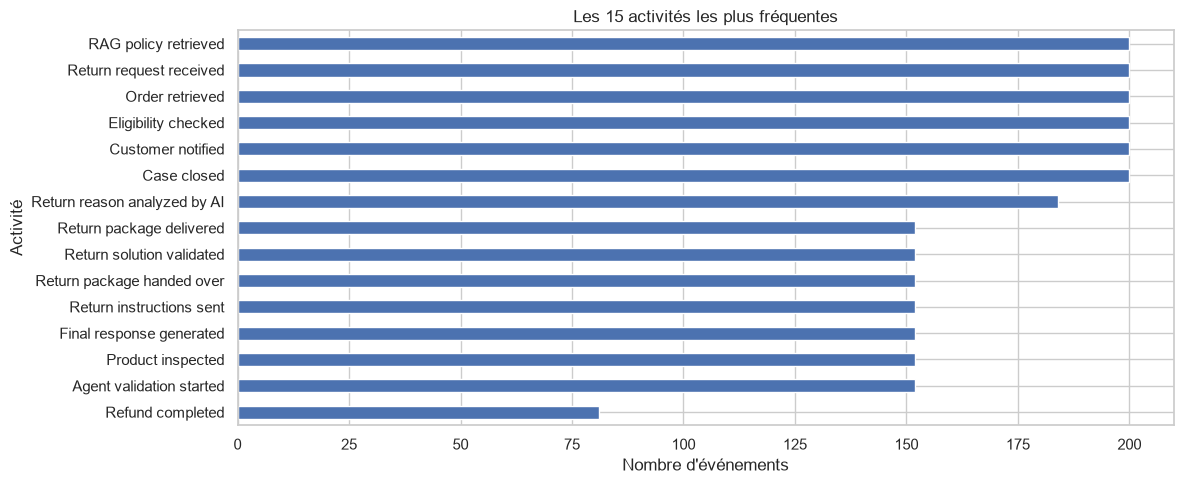

In [57]:
n_cases = df[CASE_COL].nunique()
n_events = len(df)
n_activities = df[ACT_COL].nunique()

print(f"Nombre de cas       : {n_cases:,}")
print(f"Nombre d'événements : {n_events:,}")
print(f"Nombre d'activités  : {n_activities:,}")
print(f"Événements par cas  : {n_events / n_cases:.2f}")

activity_counts = df[ACT_COL].value_counts()
display(activity_counts.rename("nombre_evenements").to_frame().head(20))

plt.figure(figsize=(12, 5))
activity_counts.head(15).sort_values().plot(kind="barh")
plt.title("Les 15 activités les plus fréquentes")
plt.xlabel("Nombre d'événements")
plt.ylabel("Activité")
plt.tight_layout()
plt.show()

### 5.2 Nombre d'événements par cas

,nb_evenements
count,200.000000
mean,14.865000
std,3.434495
min,9.000000
25%,16.000000
50%,16.000000
75%,17.000000
max,19.000000


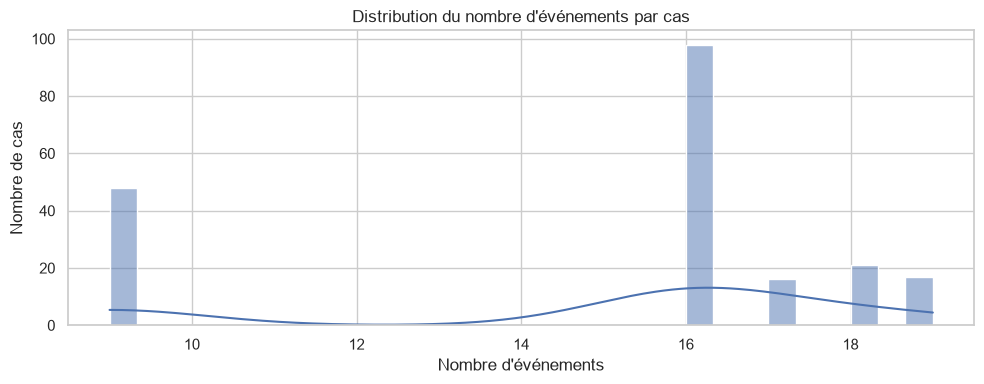

In [24]:
events_per_case = df.groupby(CASE_COL).size().rename("nb_evenements")
display(events_per_case.describe().to_frame())

plt.figure(figsize=(10, 4))
sns.histplot(events_per_case, bins=30, kde=True)
plt.title("Distribution du nombre d'événements par cas")
plt.xlabel("Nombre d'événements")
plt.ylabel("Nombre de cas")
plt.tight_layout()
plt.show()

### 5.3 Durée totale des cas

count                       200
mean     4 days 03:11:04.690000
std      2 days 13:56:35.425908
min             0 days 00:17:00
25%      2 days 19:35:20.500000
50%             4 days 23:50:33
75%      5 days 23:20:42.750000
max             8 days 11:48:43
Name: duree, dtype: object

,debut,fin,duree,duree_heures,duree_jours
case:concept:name,,,,,
RMA-0167,2026-10-14 13:35:00,2026-10-23 01:23:43,8 days 11:48:43,203.811944,8.492164
RMA-0041,2026-10-10 18:15:00,2026-10-19 03:05:47,8 days 08:50:47,200.846389,8.368600
RMA-0129,2026-09-11 18:19:00,2026-09-20 01:27:28,8 days 07:08:28,199.141111,8.297546
RMA-0077,2026-10-17 13:48:00,2026-10-25 19:12:34,8 days 05:24:34,197.409444,8.225394
RMA-0023,2026-09-25 12:48:00,2026-10-03 14:19:40,8 days 01:31:40,193.527778,8.063657
RMA-0075,2026-10-16 13:46:00,2026-10-24 13:24:58,7 days 23:38:58,191.649444,7.985394
RMA-0102,2026-10-06 16:32:00,2026-10-14 13:21:55,7 days 20:49:55,188.831944,7.867998
RMA-0098,2026-10-22 10:06:00,2026-10-30 06:20:05,7 days 20:14:05,188.234722,7.843113
RMA-0070,2026-09-14 17:18:00,2026-09-22 10:10:28,7 days 16:52:28,184.874444,7.703102


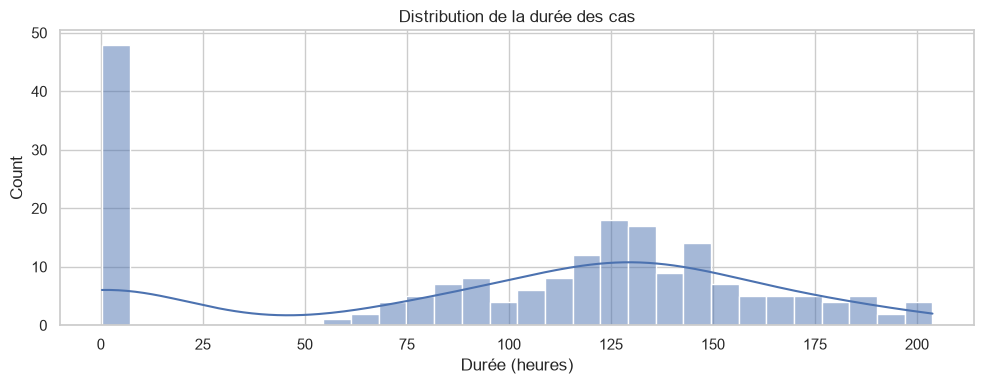

In [13]:
case_times = df.groupby(CASE_COL)[TIME_COL].agg(
    debut="min",
    fin="max"
)
case_times["duree"] = case_times["fin"] - case_times["debut"]
case_times["duree_heures"] = case_times["duree"].dt.total_seconds() / 3600
case_times["duree_jours"] = case_times["duree"].dt.total_seconds() / 86400

display(case_times["duree"].describe())
display(case_times.sort_values("duree", ascending=False).head(10))

plt.figure(figsize=(10, 4))
sns.histplot(case_times["duree_heures"].clip(lower=0), bins=30, kde=True)
plt.title("Distribution de la durée des cas")
plt.xlabel("Durée (heures)")
plt.tight_layout()
plt.show()

**Interprétation :** une durée élevée peut signaler un dossier complexe, une attente ou une exception. Elle ne prouve pas à elle seule qu'il existe un dysfonctionnement : il faut examiner les activités et le contexte métier.

## 6. Découverte du processus (Process Discovery)

### 6.1 Création du Event Log PM4Py

In [25]:
import os
import shutil
os.environ["PATH"] = (
    r"C:\Program Files\Graphviz\bin"
    + os.pathsep
    + os.environ["PATH"]
)

# df respecte déjà les noms de colonnes standards PM4Py
event_log = pm4py.convert_to_event_log(df)
print("Event Log créé :", len(event_log), "cas")



Event Log créé : 200 cas


### 6.2 Directly-Follows Graph (DFG)

Activités de début : {'Return request received': 200}
Activités de fin   : {'Case closed': 200}
Nombre de transitions : 42


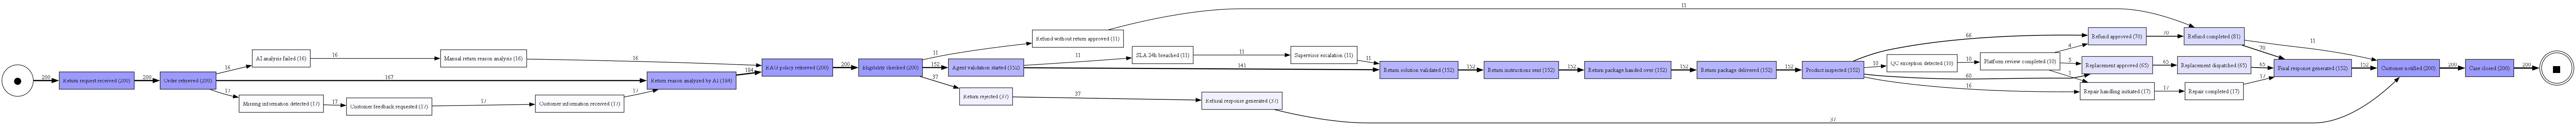

In [18]:
dfg, start_activities, end_activities = pm4py.discover_dfg(event_log)

print("Activités de début :", start_activities)
print("Activités de fin   :", end_activities)
print("Nombre de transitions :", len(dfg))

# Visualisation DFG : les fréquences indiquent le nombre de fois
# où une activité est directement suivie d'une autre.
pm4py.view_dfg(dfg, start_activities, end_activities)

**Lecture du DFG :** un arc A → B signifie qu'au moins un cas a exécuté B juste après A. Le poids de l'arc représente la fréquence de cette succession. Le DFG montre les chemins observés, mais ne décrit pas à lui seul toutes les règles du processus.

### 6.3 Découverte avec Inductive Miner et réseau de Petri

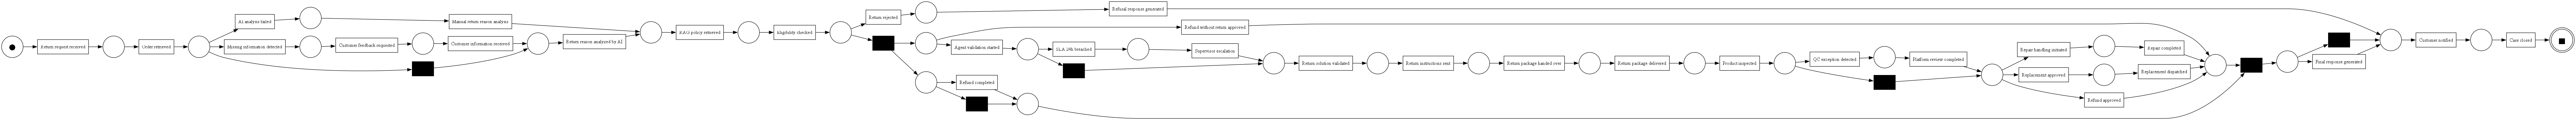

Réseau de Petri découvert.


In [26]:
# Découvrir un modèle de processus à partir du journal
net, im, fm = pm4py.discover_petri_net_inductive(event_log)

# Visualiser le réseau de Petri
pm4py.view_petri_net(net, im, fm)

print("Réseau de Petri découvert.")

## 7. Analyse des variantes

,variante,nb_cas,pourcentage
4,Return request received → Order retrieved → Return reason analyzed by AI → RAG policy retrieved → Eligibility checke...,45,22.5
2,Return request received → Order retrieved → Return reason analyzed by AI → RAG policy retrieved → Eligibility checke...,41,20.5
6,Return request received → Order retrieved → Return reason analyzed by AI → RAG policy retrieved → Eligibility checke...,37,18.5
9,Return request received → Order retrieved → Return reason analyzed by AI → RAG policy retrieved → Eligibility checke...,12,6.0
7,Return request received → Order retrieved → Return reason analyzed by AI → RAG policy retrieved → Eligibility checke...,11,5.5
0,Return request received → Order retrieved → Missing information detected → Customer feedback requested → Customer in...,10,5.0
8,Return request received → Order retrieved → AI analysis failed → Manual return reason analysis → RAG policy retrieve...,7,3.5
3,Return request received → Order retrieved → Missing information detected → Customer feedback requested → Customer in...,7,3.5
10,Return request received → Order retrieved → AI analysis failed → Manual return reason analysis → RAG policy retrieve...,7,3.5
1,Return request received → Order retrieved → Return reason analyzed by AI → RAG policy retrieved → Eligibility checke...,5,2.5


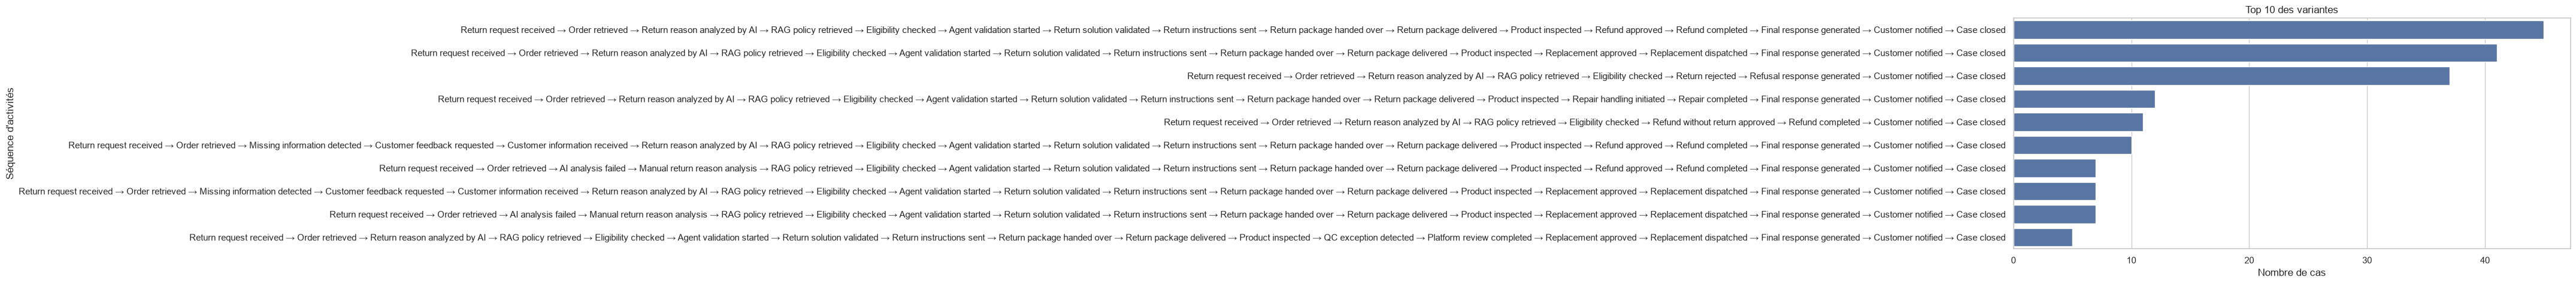

In [29]:
# Une variante = une séquence d'activités suivie par un ou plusieurs cas
variants = pm4py.get_variants_as_tuples(event_log)

variant_rows = [
    {"variante": " → ".join(variant), "nb_cas": len(cases)}
    for variant, cases in variants.items()
]
variants_df = pd.DataFrame(variant_rows)

if not variants_df.empty:
    variants_df["pourcentage"] = (
        variants_df["nb_cas"] / n_cases * 100
    ).round(2)
    variants_df = variants_df.sort_values("nb_cas", ascending=False)

display(variants_df.head(20))

top_variants = variants_df.head(10).copy()
if not top_variants.empty:
    plt.figure(figsize=(12, 5))
    sns.barplot(data=top_variants, x="nb_cas", y="variante")
    plt.title("Top 10 des variantes")
    plt.xlabel("Nombre de cas")
    plt.ylabel("Séquence d'activités")
    plt.tight_layout()
    plt.show()

**Questions métier :**
- Quelle est la variante la plus fréquente ?
- Quelle part des cas suit le parcours principal ?
- Les variantes rares sont-elles des exceptions légitimes ou des parcours à examiner ?

## 8. Analyse des performances

### 8.1 Temps entre deux événements successifs

In [30]:
# Calculer le temps écoulé depuis l'événement précédent du même cas
performance_df = df.sort_values([CASE_COL, TIME_COL]).copy()
performance_df["activite_suivante"] = performance_df.groupby(CASE_COL)[ACT_COL].shift(-1)
performance_df["timestamp_suivant"] = performance_df.groupby(CASE_COL)[TIME_COL].shift(-1)
performance_df["temps_attente"] = (
    performance_df["timestamp_suivant"] - performance_df[TIME_COL]
)
performance_df["attente_heures"] = (
    performance_df["temps_attente"].dt.total_seconds() / 3600
)

transitions = performance_df.dropna(subset=["activite_suivante"]).copy()
transition_stats = (
    transitions.groupby([ACT_COL, "activite_suivante"])["attente_heures"]
    .agg(["count", "mean", "median", "max"])
    .sort_values("mean", ascending=False)
)
display(transition_stats.head(20))

,,count,mean,median,max
concept:name,activite_suivante,,,,
Return package handed over,Return package delivered,152,68.470832,72.565694,106.610000
Repair handling initiated,Repair completed,17,46.567696,46.465000,71.365833
Return instructions sent,Return package handed over,152,30.847710,30.587500,59.860278
Agent validation started,SLA 24h breached,11,30.347298,30.240000,33.535278
Refund approved,Refund completed,70,12.000151,11.311944,23.947222
Missing information detected,Customer feedback requested,17,10.707010,11.124722,19.056389
Replacement approved,Replacement dispatched,65,10.140594,9.706389,17.921389
QC exception detected,Platform review completed,10,9.629139,9.880000,15.435833
Customer feedback requested,Customer information received,17,7.973840,6.329444,17.954444


### 8.2 Temps d'attente par transition

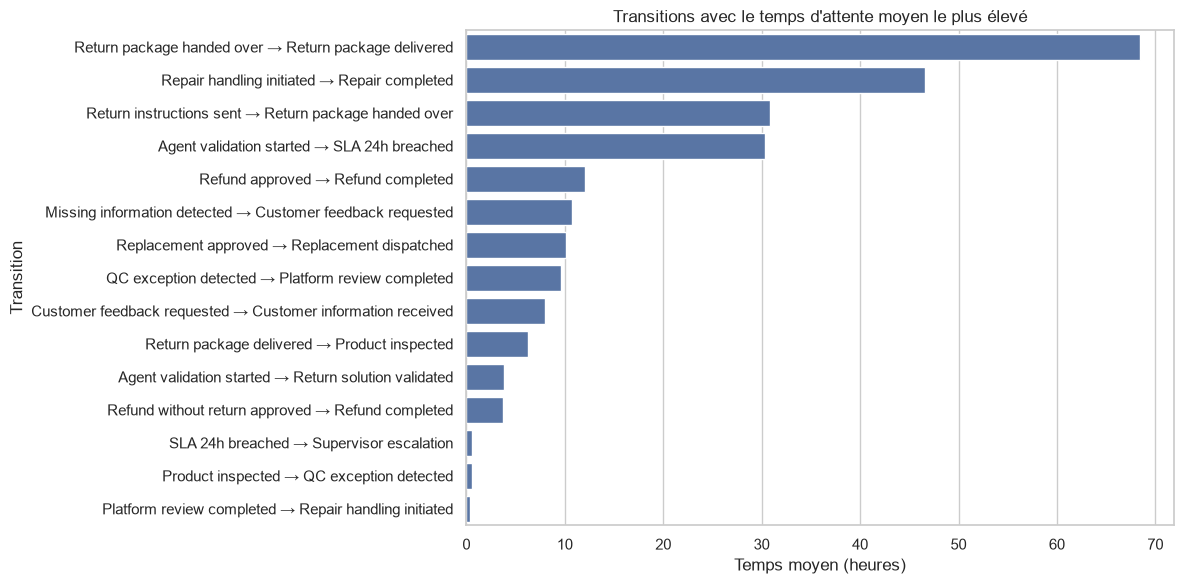

In [31]:
top_waits = transition_stats.reset_index().head(15).copy()
top_waits["transition"] = (
    top_waits[ACT_COL].astype(str) + " → " +
    top_waits["activite_suivante"].astype(str)
)

if not top_waits.empty:
    plt.figure(figsize=(12, 6))
    sns.barplot(data=top_waits, x="mean", y="transition")
    plt.title("Transitions avec le temps d'attente moyen le plus élevé")
    plt.xlabel("Temps moyen (heures)")
    plt.ylabel("Transition")
    plt.tight_layout()
    plt.show()

### 8.3 Activités les plus longues (temps entre deux événements)

In [32]:
activity_wait = (
    transitions.groupby(ACT_COL)["attente_heures"]
    .agg(nb_observations="count", attente_moyenne_h="mean",
         attente_mediane_h="median")
    .sort_values("attente_moyenne_h", ascending=False)
)
display(activity_wait.head(20))

,nb_observations,attente_moyenne_h,attente_mediane_h
concept:name,,,
Return package handed over,152,68.470832,72.565694
Repair handling initiated,17,46.567696,46.465000
Return instructions sent,152,30.847710,30.587500
Refund approved,70,12.000151,11.311944
Missing information detected,17,10.707010,11.124722
Replacement approved,65,10.140594,9.706389
QC exception detected,10,9.629139,9.880000
Customer feedback requested,17,7.973840,6.329444
Return package delivered,152,6.246149,6.319028


**Attention :** avec un journal qui ne contient que des timestamps d'événements, le temps entre deux événements est un temps écoulé (attente + éventuel temps de traitement). Pour mesurer précisément la durée d'exécution d'une activité, il faut généralement disposer d'événements de début et de fin ou d'une durée explicite.

## 9. Conformance Checking (conformité)

La conformité compare le comportement observé à un **modèle de référence** défini par les règles métier. Le réseau de Petri découvert automatiquement à l'étape précédente est appris à partir des mêmes données : le comparer à ces données ne remplace donc pas une véritable validation par rapport à un processus attendu.

Si tu disposes d'un modèle de référence, charge-le et utilise-le dans cette section. Le bloc ci-dessous fournit une première mesure de replay sur le modèle découvert, à interpréter comme un diagnostic exploratoire et non comme une preuve de conformité métier.

In [ ]:
# Replay exploratoire sur le modèle découvert
# Pour une véritable conformité, remplacer net, im, fm par le modèle de référence validé.
try:
    replay_fitness = pm4py.fitness_token_based_replay(
        event_log, net, im, fm
    )
    print("Token-based replay fitness (modèle découvert) :")
    display(replay_fitness)
except Exception as exc:
    print("Replay non disponible avec cette configuration PM4Py :", exc)

# Alignements : plus coûteux en calcul, particulièrement sur de grands journaux.
# Lancer seulement si le dataset est de taille raisonnable.
RUN_ALIGNMENTS = False

if RUN_ALIGNMENTS:
    try:
        alignments = pm4py.conformance_diagnostics_alignments(
            event_log, net, im, fm
        )
        print("Nombre d'alignements :", len(alignments))
        display(pd.DataFrame(alignments).head())
    except Exception as exc:
        print("Alignements non disponibles :", exc)

## 10. Détection de parcours atypiques

Cette section utilise une règle simple et explicable : les variantes rares sont signalées pour inspection. Le seuil est un paramètre à adapter au volume et au contexte métier. Une variante rare n'est pas automatiquement une anomalie.

In [49]:
# Seuil configurable : variantes représentant moins de 1 % des cas
RARE_VARIANT_THRESHOLD = 1.0

rare_variants = variants_df[
    variants_df["pourcentage"] < RARE_VARIANT_THRESHOLD
].copy()

print("Nombre de variantes rares :", len(rare_variants))
display(rare_variants.head(30))

Nombre de variantes rares : 1


,variante,nb_cas,pourcentage
15,Return request received → Order retrieved → Return reason analyzed by AI → RAG policy retrieved → Eligibility checke...,1,0.5


### Détecter les cas de durée élevée (IQR)

In [34]:
q1 = case_times["duree_heures"].quantile(0.25)
q3 = case_times["duree_heures"].quantile(0.75)
iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr

long_cases = case_times[
    case_times["duree_heures"] > upper_bound
].sort_values("duree_heures", ascending=False)

print(f"Seuil IQR supérieur : {upper_bound:.2f} heures")
print("Nombre de cas à durée élevée :", len(long_cases))
display(long_cases.head(20))

Seuil IQR supérieur : 256.98 heures
Nombre de cas à durée élevée : 0


,debut,fin,duree,duree_heures,duree_jours
case:concept:name,,,,,


**Interprétation :** les cas signalés doivent être analysés avec les séquences d'activités, les transitions et les informations métier. Le seuil IQR est une méthode statistique exploratoire, pas une décision automatique.

## 11. Synthèse des indicateurs

In [50]:
summary = pd.Series({
    "Nombre de cas": n_cases,
    "Nombre d'événements": n_events,
    "Nombre d'activités": n_activities,
    "Nombre de variantes": len(variants_df),
    "Durée médiane des cas (heures)": case_times["duree_heures"].median(),
    "Durée moyenne des cas (heures)": case_times["duree_heures"].mean(),
    "Nombre de cas à durée élevée (IQR)": len(long_cases),
    "Nombre de variantes rares": len(rare_variants)
}, name="Valeur")

display(summary.to_frame())

,Valeur
Nombre de cas,200.000000
Nombre d'événements,2973.000000
Nombre d'activités,32.000000
Nombre de variantes,16.000000
Durée médiane des cas (heures),119.842500
Durée moyenne des cas (heures),99.184636
Nombre de cas à durée élevée (IQR),0.000000
Nombre de variantes rares,1.000000


## 12. Construire les recommandations métier

In [35]:
# Quelques éléments factuels à examiner avant de rédiger les recommandations
print("1) Activités les plus fréquentes")
display(activity_counts.head(10).to_frame("événements"))

print("2) Transitions avec attente moyenne élevée")
display(transition_stats.head(10))

print("3) Variantes les plus fréquentes")
display(variants_df.head(10))

print("4) Cas avec durée élevée")
display(long_cases.head(10))

1) Activités les plus fréquentes


,événements
concept:name,
Return request received,200
Order retrieved,200
RAG policy retrieved,200
Eligibility checked,200
Customer notified,200
Case closed,200
Return reason analyzed by AI,184
Agent validation started,152
Return solution validated,152


2) Transitions avec attente moyenne élevée


,,count,mean,median,max
concept:name,activite_suivante,,,,
Return package handed over,Return package delivered,152,68.470832,72.565694,106.610000
Repair handling initiated,Repair completed,17,46.567696,46.465000,71.365833
Return instructions sent,Return package handed over,152,30.847710,30.587500,59.860278
Agent validation started,SLA 24h breached,11,30.347298,30.240000,33.535278
Refund approved,Refund completed,70,12.000151,11.311944,23.947222
Missing information detected,Customer feedback requested,17,10.707010,11.124722,19.056389
Replacement approved,Replacement dispatched,65,10.140594,9.706389,17.921389
QC exception detected,Platform review completed,10,9.629139,9.880000,15.435833
Customer feedback requested,Customer information received,17,7.973840,6.329444,17.954444


3) Variantes les plus fréquentes


,variante,nb_cas,pourcentage
4,Return request received → Order retrieved → Return reason analyzed by AI → RAG policy retrieved → Eligibility checke...,45,22.5
2,Return request received → Order retrieved → Return reason analyzed by AI → RAG policy retrieved → Eligibility checke...,41,20.5
6,Return request received → Order retrieved → Return reason analyzed by AI → RAG policy retrieved → Eligibility checke...,37,18.5
9,Return request received → Order retrieved → Return reason analyzed by AI → RAG policy retrieved → Eligibility checke...,12,6.0
7,Return request received → Order retrieved → Return reason analyzed by AI → RAG policy retrieved → Eligibility checke...,11,5.5
0,Return request received → Order retrieved → Missing information detected → Customer feedback requested → Customer in...,10,5.0
8,Return request received → Order retrieved → AI analysis failed → Manual return reason analysis → RAG policy retrieve...,7,3.5
3,Return request received → Order retrieved → Missing information detected → Customer feedback requested → Customer in...,7,3.5
10,Return request received → Order retrieved → AI analysis failed → Manual return reason analysis → RAG policy retrieve...,7,3.5
1,Return request received → Order retrieved → Return reason analyzed by AI → RAG policy retrieved → Eligibility checke...,5,2.5


4) Cas avec durée élevée


,debut,fin,duree,duree_heures,duree_jours
case:concept:name,,,,,


### Guide de rédaction des recommandations

Pour chaque constat, rédige :
1. **Constat mesuré :** quel indicateur ou quelle visualisation le montre ?
2. **Impact potentiel :** délai, coût, charge ou expérience utilisateur.
3. **Hypothèse explicative :** quelle cause pourrait expliquer le résultat ?
4. **Action proposée :** automatisation, clarification d'une règle, répartition de charge, etc.
5. **Indicateur de suivi :** comment vérifier que l'amélioration fonctionne ?

Ne présente pas une hypothèse comme un fait si le dataset ne permet pas de la vérifier.

## 13. Export des résultats

In [52]:
reports_dir = Path("/reports")
reports_dir.mkdir(parents=True, exist_ok=True)

activity_counts.rename("nb_evenements").to_csv(
    reports_dir / "activity_frequencies.csv"
)
variants_df.to_csv(reports_dir / "variants.csv", index=False)
case_times.to_csv(reports_dir / "case_durations.csv")
transition_stats.to_csv(reports_dir / "transition_performance.csv")

summary.to_csv(reports_dir / "summary_metrics.csv", header=True)

print("Exports enregistrés dans :", reports_dir.resolve())

Exports enregistrés dans : C:\reports


## 14. Conclusion

À la fin de l'analyse, tu dois pouvoir répondre à ces questions :

- Quel est le parcours le plus fréquent ?
- Quelles variantes existent et quelle est leur fréquence ?
- Quelles transitions présentent les attentes les plus élevées ?
- Quels cas ont une durée inhabituelle ?
- Le processus observé respecte-t-il un modèle métier de référence ?
- Quelles améliorations sont justifiées par les données ?

### Limites à documenter
- Qualité et couverture du journal d'événements.
- Événements ou timestamps manquants.
- Absence éventuelle de modèle de référence.
- Différence entre temps écoulé et temps réel de traitement.
- Les parcours rares ne sont pas nécessairement incorrects.

**Prochaine étape :** exécuter le notebook cellule par cellule, vérifier les résultats et adapter les interprétations au métier représenté par ton dataset.